## Citrus
## Load SRA Run Table and First Filters

In [1]:
import pandas as pd
import numpy as np
pd.set_option("display.max_rows", None)
import missingno as msno
import regex as re

In [2]:
organism_keyword = 'CITRUS'

In [3]:
df = pd.read_csv('../../raw/citrus/01_SraRunTable.csv', low_memory=False)

In [4]:
# Select only 'Plant' in the 'BioSampleModel' column
df = df[df['BioSampleModel'] == 'Plant']
# Remove empty columns
df = df.dropna(axis=1, how='all')

In [5]:
organisms_to_keep = ['CITRUS', 'Citrus', 'citrus']
# Extend with other family's members if needed
family_members = ['Atalantia buxifolia',
 'Clausena anisata',
 'Clausena harmandiana',
 'Clausena lansium',
 'Clymenia polyandra',
 'Eriobotrya japonica',
 'Malus domestica',
 'Murraya koenigii',
 'Naringi crenulata',
 'Zanthoxylum armatum']
# Keep only values that contain the organism keywords
df = df[df['Organism'].str.contains('|'.join(organisms_to_keep + family_members), case=False, na=False)]
# Remove empty columns
df = df.dropna(axis=1, how='all')

<Axes: >

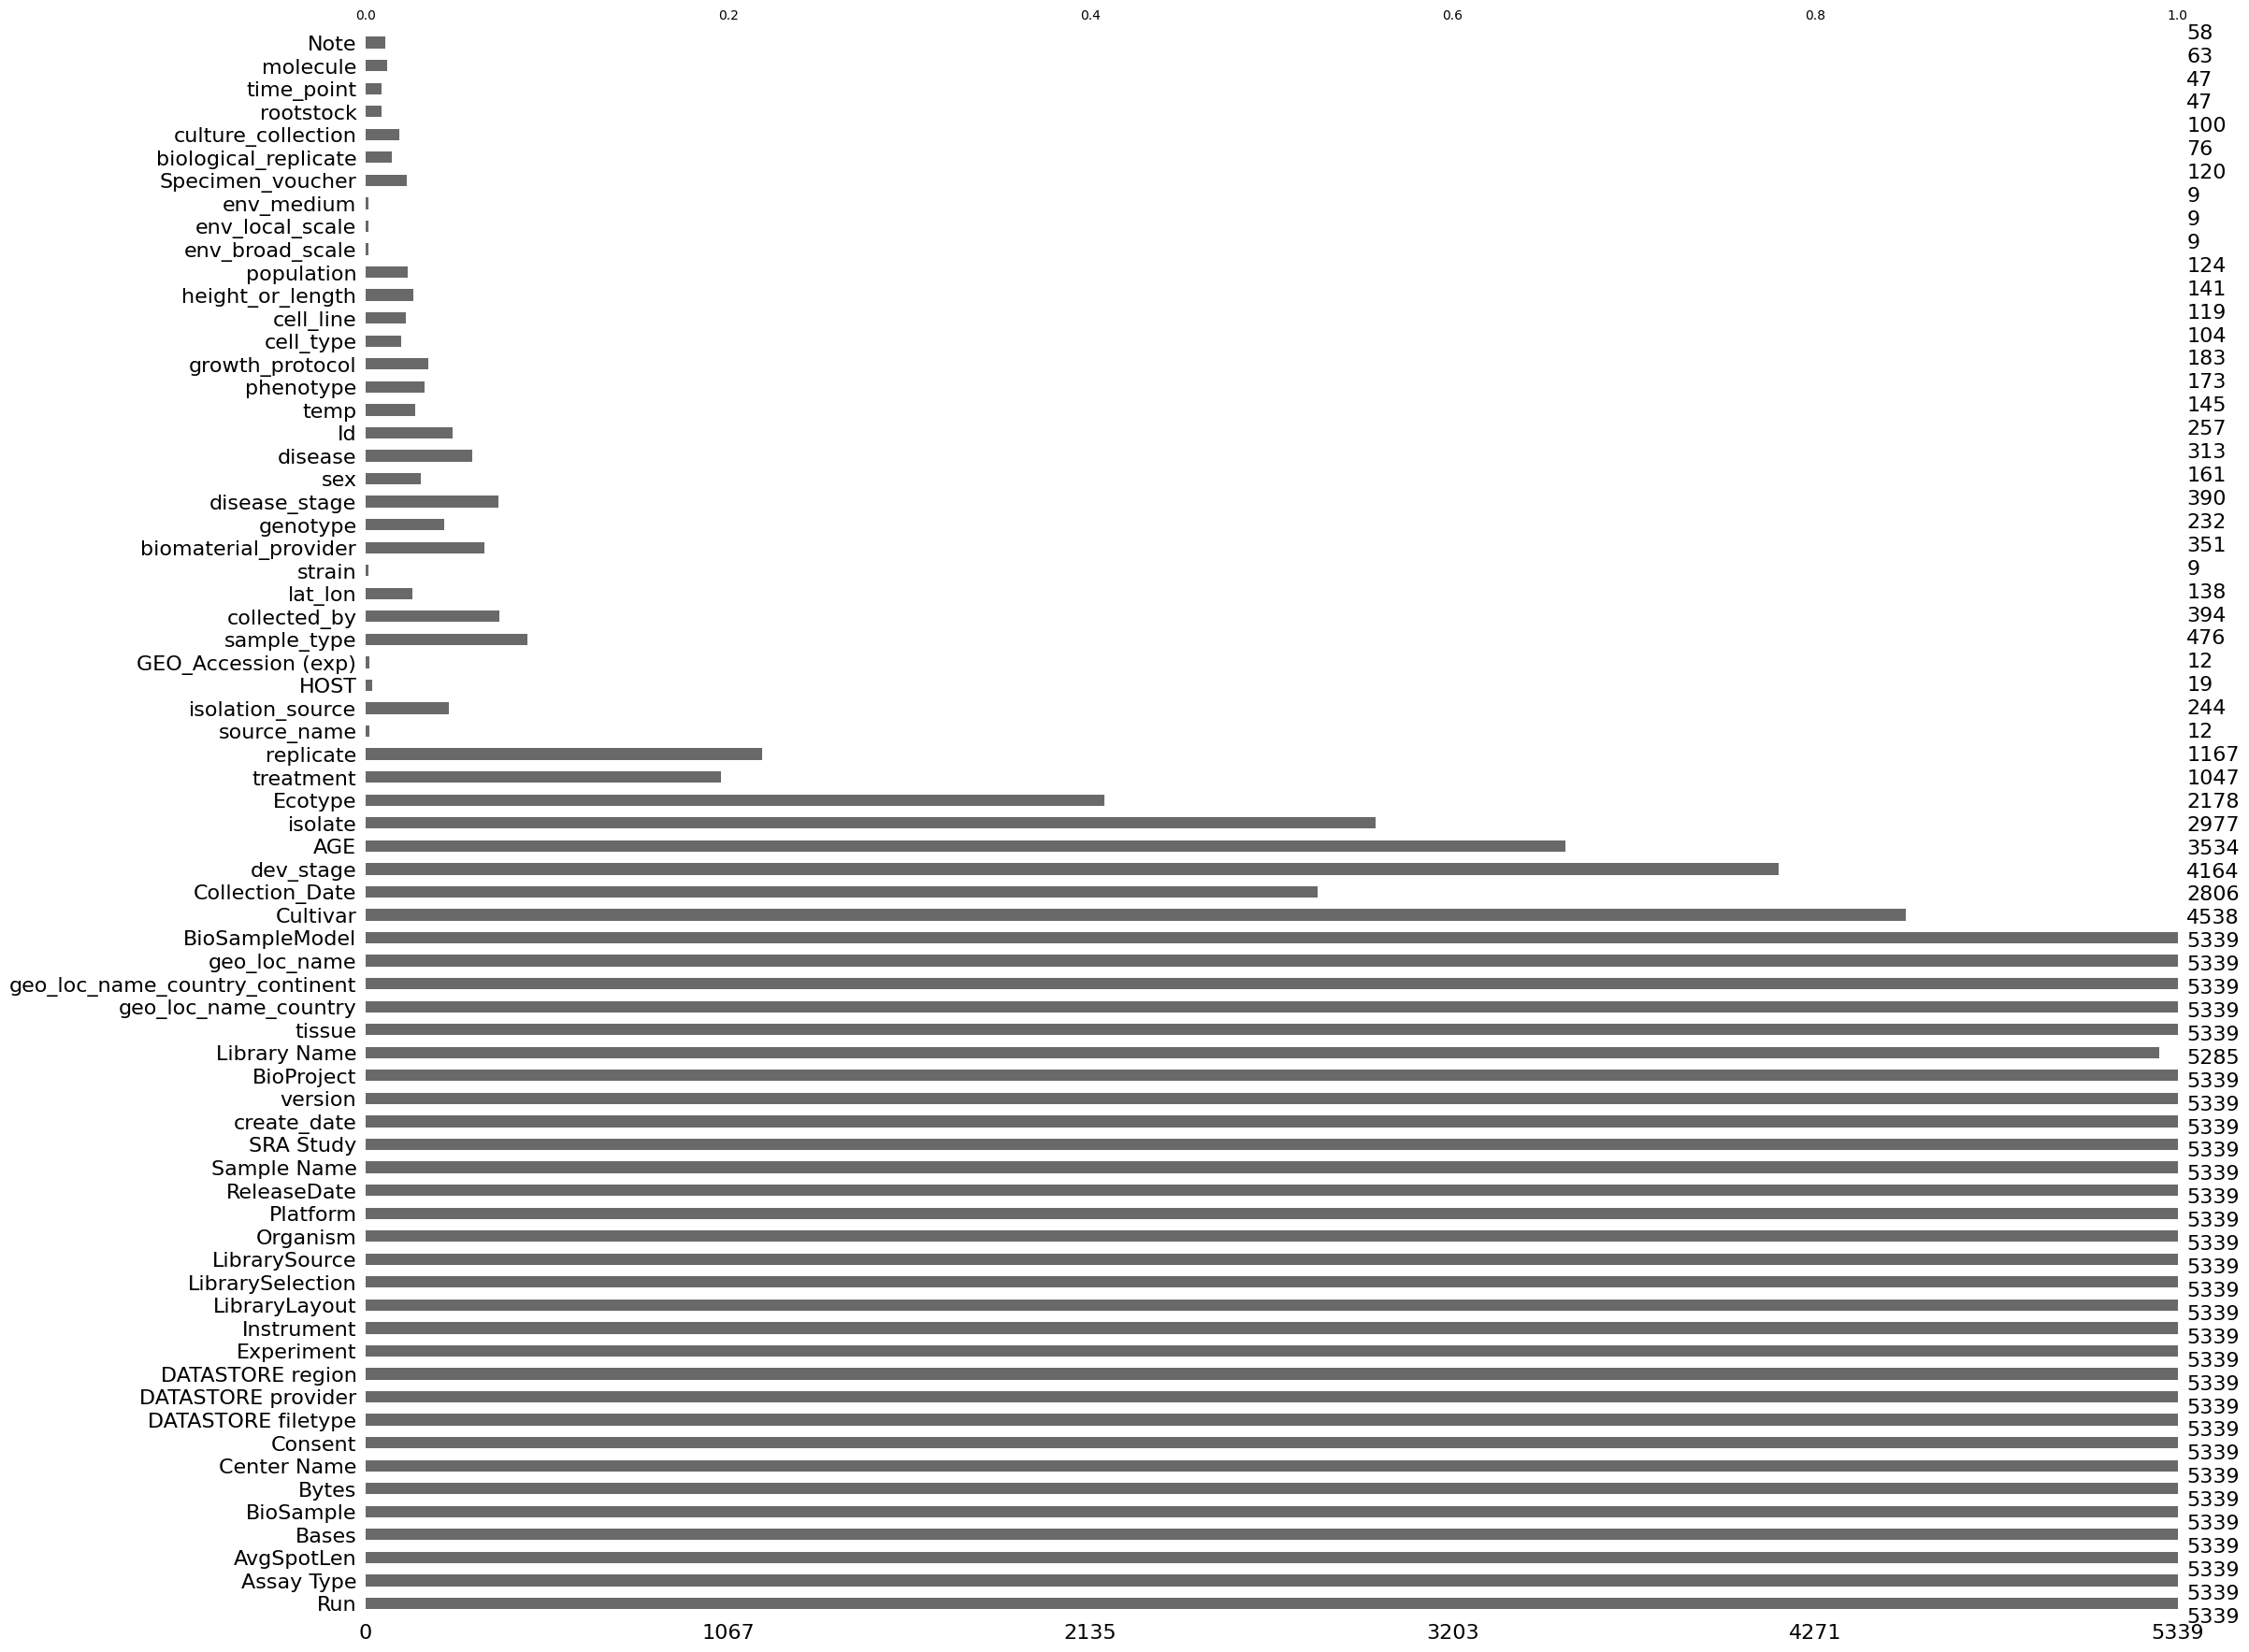

In [6]:
# Check missing values in the dataframe
msno.bar(df)

### Create Filtered Dataframe

In [7]:
# Select the columns
columns = [
    'Run',
    'Assay Type',
    'AvgSpotLen',
    'Bases',
    'BioSample',
    'Bytes',
    'Center Name',
    'Consent',
    'DATASTORE filetype',
    'DATASTORE provider',
    'DATASTORE region',
    'Experiment',
    'Instrument',
    'LibraryLayout',
    'LibrarySelection',
    'LibrarySource',
    'Organism',
    'Platform',
    'ReleaseDate',
    'Sample Name',
    'SRA Study',
    'create_date',
    'version',
    'BioProject',
    'Library Name',
    'tissue',
    'BioSampleModel',
    'Cultivar',
    'genotype',
    'disease',
    'disease_stage',
    'phenotype',
]

new_columns = [
    "geo_location",
    "growth_conditions",
    "sample_conditions",
    "replicate",
]
# Create a dataframe with only relevant columns
df_relevant = df[columns]
# Rename 'GEO_Accession (exp)' to 'GEO_Accession'
df_relevant = df_relevant.rename(columns={'GEO_Accession (exp)': 'GEO_Accession'})

In [8]:
# Replicate columns
cols_replicate = ['replicate', 'biological_replicate', 'sample_type']

# To avoid SettingWithCopyWarning, create a copy of the dataframe before modifying it
df_relevant = df_relevant.copy()

# This code creates a new 'replicate' column by combining the values from the specified columns. It handles missing values by treating them as empty strings,
# then concatenates the non-missing values with '| ' as a separator. Finally, it cleans up any trailing separators and replaces empty results with NA.
df_relevant.loc[:, "replicate"] = (
    df[cols_replicate]
    .astype(str)
    .replace(["nan", "None", "NaN"], "")
    .agg("| ".join, axis=1)
    .str.strip("| ")
    .str.replace(r"\s*\|\s*$", "", regex=True)
)

In [9]:
# Geographic location-related columns
cols_location = ['lat_lon', 'geo_loc_name_country',
    'geo_loc_name_country_continent',
    'geo_loc_name']

# To avoid SettingWithCopyWarning, create a copy of the dataframe before modifying it
df_relevant = df_relevant.copy()

# Create a new 'geo_location' column by combining the values from the specified columns. It handles missing values by treating them as empty strings,
# then concatenates the non-missing values with '| ' as a separator. Finally, it cleans up any trailing separators and replaces empty results with NA.
df_relevant.loc[:, "geo_location"] = (
    df[cols_location]
    .astype(str)
    .replace(["nan", "None", "NaN"], "")
    .agg("| ".join, axis=1)
    .str.strip("| ")
    .str.replace(r"\s*\|\s*$", "", regex=True)
)

In [10]:
# Growth conditions-related columns
cols_growth_conditions = ['growth_protocol']

# To avoid SettingWithCopyWarning, create a copy of the dataframe before modifying it
df_relevant = df_relevant.copy()

# This code creates a new 'growth_conditions' column by combining the values from the specified columns. It handles missing values by treating them as empty strings,
# then concatenates the non-missing values with '| ' as a separator. Finally, it cleans up any trailing separators and replaces empty results with NA.
df_relevant.loc[:, "growth_conditions"] = (
    df[cols_growth_conditions]
    .astype(str)
    .replace(["nan", "None", "NaN"], "")
    .agg("| ".join, axis=1)
    .str.strip("| ")
    .str.replace(r"\s*\|\s*$", "", regex=True)
)

In [11]:
# Treatment-related columns that may contain information about the treatment conditions of the samples, which we will combine into a single 'sample_conditions' column.
cols_sample_conditions = ['dev_stage',
 'AGE', 'isolate', 'Ecotype',
 'treatment', 'isolation_source', 'time_point']

# To avoid SettingWithCopyWarning, create a copy of the dataframe before modifying it
df_relevant = df_relevant.copy()

# This code creates a new 'sample_conditions' column by combining the values from the specified columns. It handles missing values by treating them as empty strings,
# then concatenates the non-missing values with '| ' as a separator. Finally, it cleans up any trailing separators and replaces empty results with NA.
df_relevant.loc[:, "sample_conditions"] = (
    df[cols_sample_conditions]
    .astype(str)
    .replace(["nan", "None", "NaN"], "")
    .agg("| ".join, axis=1)
    .str.strip("| ")
    .str.replace(r"\s*\|\s*$", "", regex=True)
)

<Axes: >

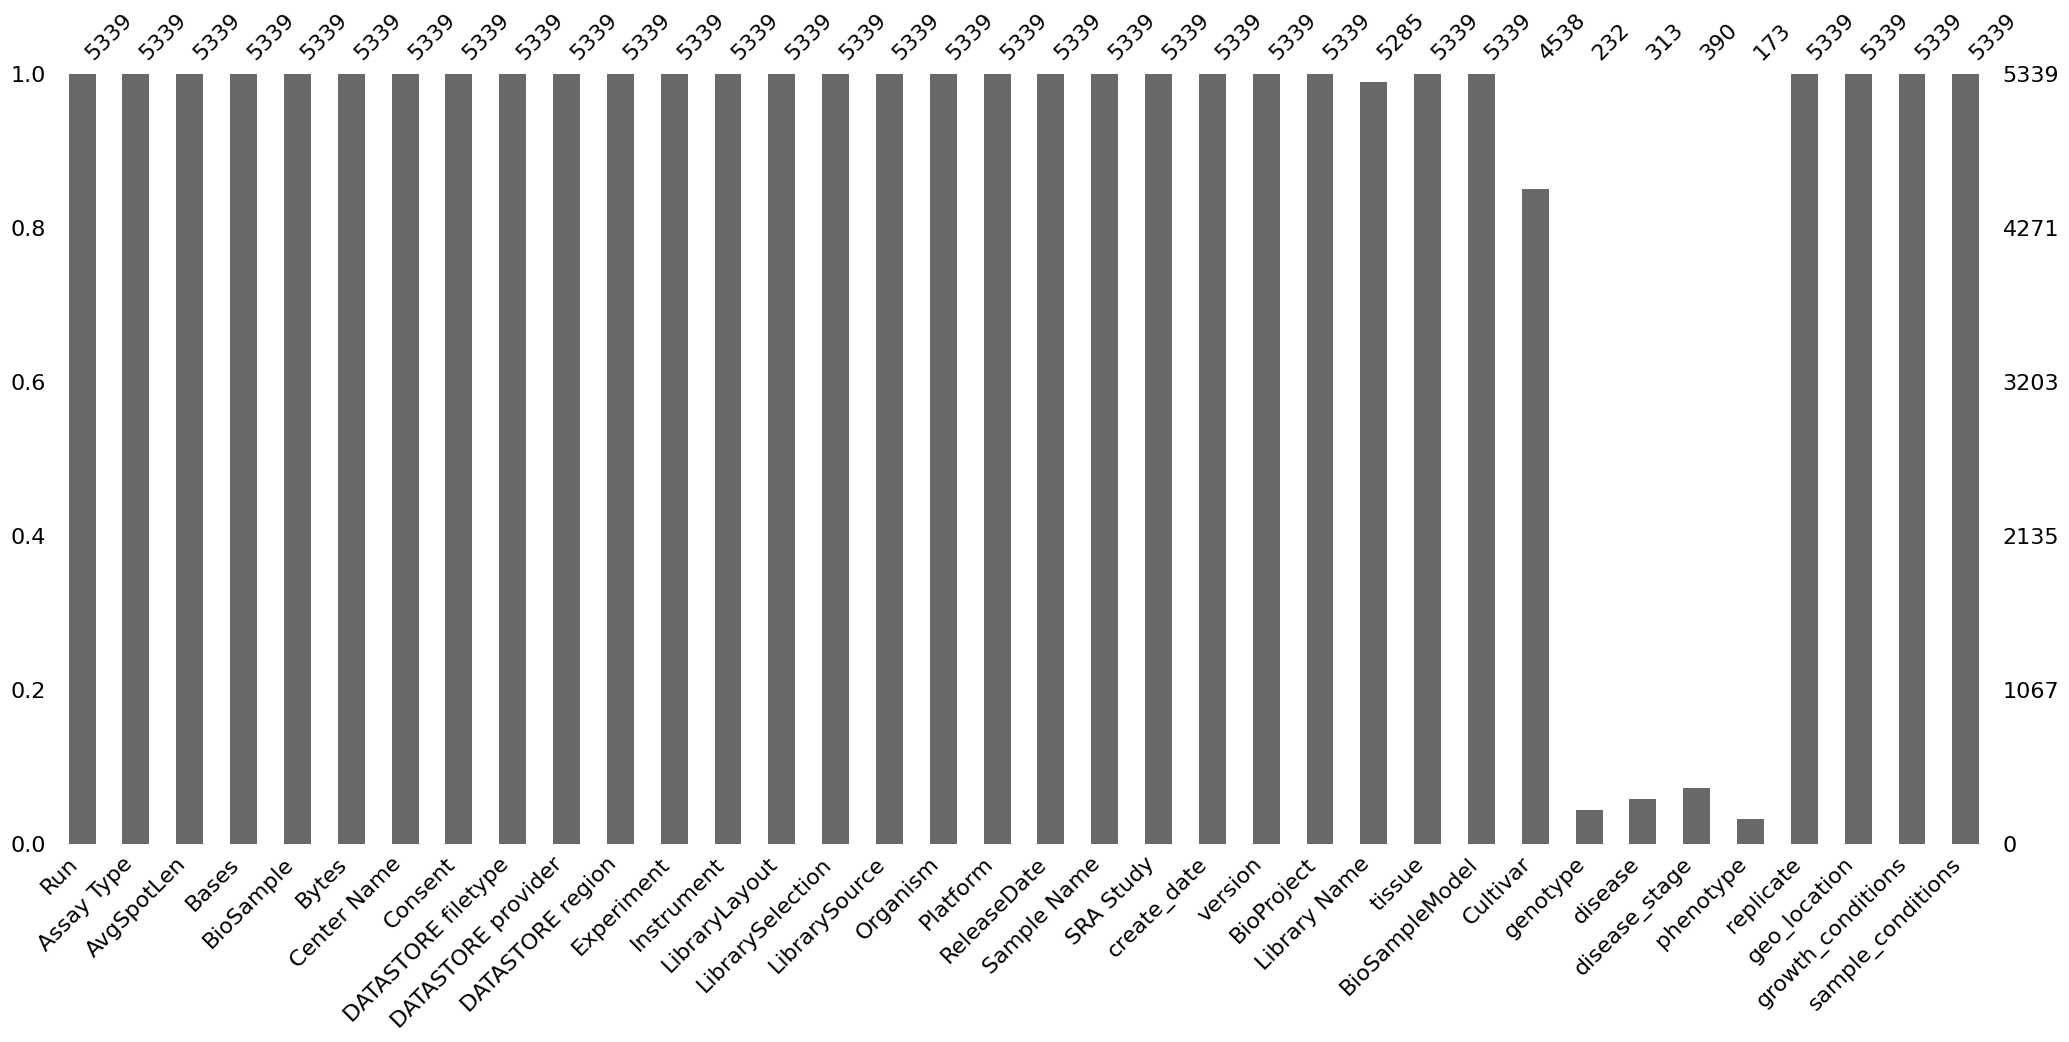

In [12]:
msno.bar(df_relevant)

In [13]:
# Create 'RunCount' column to count the number of runs per BioProject. This is done by grouping the dataframe by 'BioProject' and counting the number of 'Run' entries for each group. The result is then merged back into the original dataframe as a new column called 'RunCount'.
df_relevant['RunCount'] = df_relevant.groupby('BioProject')['Run'].transform('count')

# Sort based in the RunCount column in descending order, so that BioProjects with more runs appear first.
df_relevant = df_relevant.sort_values(by='RunCount', ascending=False)

In [14]:
# Save
df_relevant.to_csv('../../raw/citrus/02_SraRunTable_relevant.csv', index=False)